# Exploratory data analysis: early fake news detection

Four propagation-cascade datasets, prepared by `src/build_data.py` (see README, section *Data*):

* **PolitiFact**, **GossipCop** (UPFD): news articles and the Twitter posts spreading them, label real / fake.
* **Twitter15**, **Twitter16** (Ma et al. 2017): source tweets and their retweet/reply trees, labels
  non-rumor / false / true / unverified.

Every cascade is a rooted tree, nodes in time order (`node_idx` 0 = root), so an *early window* (the first *h* hours
or the first *k* engagements) is a prefix of the node table. The project question is how early fake and real
cascades can be told apart, so beyond basic statistics the analysis focuses on **what is observable in early
windows**.

Unless stated otherwise we use the binary label (1 = fake): for Twitter, *false* = fake, *true* + *non-rumor* = real,
*unverified* is excluded. Figures are also saved to `artifacts/eda/`.

Run: `uv run --with jupyter jupyter lab notebooks/eda.ipynb` (after `download_data.sh` and `src/build_data.py`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, OUT = ROOT / "data" / "processed", ROOT / "artifacts" / "eda"
OUT.mkdir(parents=True, exist_ok=True)
DATASETS = ["politifact", "gossipcop", "twitter15", "twitter16"]
TITLE = {"politifact": "PolitiFact", "gossipcop": "GossipCop", "twitter15": "Twitter15", "twitter16": "Twitter16"}
COLOR = {0: "#2a78d6", 1: "#eb6834"}  # real = blue, fake = orange (colour-blind-safe pair)
NAME = {0: "real", 1: "fake"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"font.size": 8, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
                     "legend.frameon": False, "figure.dpi": 120, "savefig.dpi": 200, "savefig.bbox": "tight"})
pd.set_option("display.precision", 3)


def wlabel(h):
    return "full" if h is None else f"{h * 60:.0f} min" if h < 1 else f"{h:g} h"


def panels(n_rows=1, h=1.9):
    return plt.subplots(n_rows, 4, figsize=(7.2, h * n_rows), squeeze=False)


def ecdf(ax, x, color, label):
    x = np.sort(np.asarray(x))
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=color, label=label)


def auc(y, x):
    a = roc_auc_score(y, x)
    return max(a, 1 - a)  # direction-free separability: 0.5 = no signal, 1 = perfect

## 0. Data model: cascades, nodes and relations

Processed data (`data/processed/<dataset>/`, built by `src/build_data.py`) consists of three tables:

| table | one row = | key | relations |
|---|---|---|---|
| `graphs` | one cascade (news item / source tweet) with its label | `graph_id` | 1 graph : N nodes |
| `nodes` | one node of the propagation tree | (`graph_id`, `node_idx`) | `parent_idx` → `node_idx` of the same graph (root: -1); UPFD `feat_row` → row of the raw feature matrix |
| `edges_raw` (Twitter only) | one raw edge before cleaning | (`graph_id`, `src_idx`, `dst_idx`) | both ends → `nodes`; `in_tree` marks the edges kept as parent links |

What the elements mean in the two dataset families:

| | UPFD (PolitiFact, GossipCop) | Twitter15/16 |
|---|---|---|
| root (`node_idx` 0) | the news article (no own timestamp) | the source tweet |
| node | a post sharing the news; one user may post several times | a user who retweeted/replied; once per tree |
| edge parent → child | child post spread from the parent (news → first-level posts, post → retweet), as reconstructed by UPFD | child engaged after and from the parent; ambiguous parents resolved by the latest earlier candidate |
| time `t_min` | minutes since the first engagement (raw UNIX time kept) | minutes since the source tweet (raw delay kept) |
| node features | user-history BERT (768), spaCy (300), profile (10) | none (only user id); text of the source tweet |
| label | per cascade: real / fake | per cascade: non-rumor / false / true / unverified |

Invariants that hold for every cascade: exactly one root, `parent_idx < node_idx`, parent time ≤ child time,
`depth = parent depth + 1`. Because nodes are in time order, an **early window** is a prefix of the node table:
all nodes with `t_min ≤ h` (or the first *k* nodes) always form a connected tree. The same window can be fed to a
model in two representations, which is the comparison our project is about:

* **graph**: the window's nodes plus their parent edges (input of a GNN);
* **sequence**: the same nodes ordered by time, without edges (input of a recurrent model).

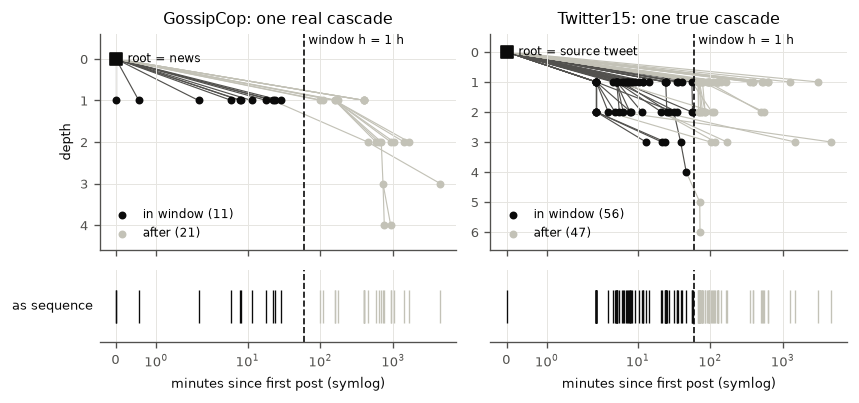

In [2]:
EXAMPLES = [("gossipcop", 38, "GossipCop", "news"), ("twitter15", "407205404075376640", "Twitter15", "source tweet")]
H_EX = 60  # window: first hour (minutes)
LATE = "#c3c2b7"

fig, axes = plt.subplots(2, 2, figsize=(7.2, 3.4), height_ratios=[3, 1], sharex="col")
for j, (n, gid, name, root_name) in enumerate(EXAMPLES):
    v = pd.read_parquet(DATA / n / "nodes.parquet", filters=[("graph_id", "==", gid)])
    lab = pd.read_parquet(DATA / n / "graphs.parquet", filters=[("graph_id", "==", gid)]).label_name.iloc[0]
    x, d = v.t_min.to_numpy(), v.depth.to_numpy()
    early = x <= H_EX
    ax, sx = axes[0, j], axes[1, j]
    for i, p in enumerate(v.parent_idx):
        if p >= 0:
            ax.plot([x[p], x[i]], [d[p], d[i]], color=INK2 if early[i] else LATE, lw=0.7, zorder=1)
    ax.scatter(x[early], d[early], s=14, color=INK, zorder=2, label=f"in window ({early.sum() - 1})")
    ax.scatter(x[~early], d[~early], s=14, color=LATE, zorder=2, label=f"after ({(~early).sum()})")
    ax.scatter([0], [0], s=60, marker="s", color=INK, zorder=3)
    ax.annotate(f"root = {root_name}", (0, 0), xytext=(7, -2), textcoords="offset points", fontsize=7)
    ax.set(xscale="symlog", ylim=(d.max() + 0.6, -0.6), title=f"{name}: one {lab} cascade", ylabel="depth" if j == 0 else None)
    ax.legend(loc="lower left", frameon=False, fontsize=7)
    sx.eventplot([x[early]], colors=INK, linelengths=0.8, lw=0.8)
    sx.eventplot([x[~early]], colors=LATE, linelengths=0.8, lw=0.8)
    sx.set(xscale="symlog", yticks=[], xlabel="minutes since first post (symlog)")
    sx.spines["left"].set_visible(False)
    for a in (ax, sx):
        a.axvline(H_EX, color=INK, lw=1, ls="--")
    ax.text(H_EX, -0.6, " window h = 1 h", va="top", fontsize=7)
axes[1, 0].set_ylabel("as sequence", rotation=0, ha="right", va="center")
fig.tight_layout()
fig.savefig(OUT / "fig0_cascade_example.png")

Top: the propagation tree (x = time, y = depth); bottom: the same nodes as a time-ordered sequence.
Everything left of the dashed line is the input of an early detector with a 1-hour window.
In the GossipCop example all 11 posts of the first hour hang directly under the news node (a star) and deeper
levels appear only later; the Twitter cascade is much faster (56 of 103 users within the hour) and already
reaches depth 4. Sections 2-4 show that these two patterns are typical of their datasets.

## 1. Datasets at a glance

In [3]:
graphs_all = {n: pd.read_parquet(DATA / n / "graphs.parquet") for n in DATASETS}
nodes_all = {n: pd.read_parquet(DATA / n / "nodes.parquet",
                                columns=["graph_id", "node_idx", "parent_idx", "depth", "t_min", "user_id"])
             for n in DATASETS}

overview = pd.DataFrame.from_dict(orient="index", data={
    TITLE[n]: {"cascades": len(g), "nodes": int(g.n_nodes.sum()),
               "mean nodes / cascade": round(g.n_nodes.mean(), 1), "median max depth": g.max_depth.median(),
               "median time span (h)": round(g.t_span_min.median() / 60, 1),
               "users (unique)": nodes_all[n].query("node_idx > 0").user_id.nunique()}
    for n, g in graphs_all.items()})
overview

,cascades,nodes,mean nodes / cascade,median max depth,median time span (h),users (unique)
PolitiFact,314,41054,130.7,3.0,5266.0,30812
GossipCop,5464,314262,57.5,2.0,215.0,75914
Twitter15,1490,599196,402.1,3.0,196.1,480478
Twitter16,818,347828,425.2,3.0,194.9,289367


In [4]:
pd.concat({TITLE[n]: g.label_name.value_counts() for n, g in graphs_all.items()}, axis=1).fillna(0).astype(int)

,PolitiFact,GossipCop,Twitter15,Twitter16
label_name,,,,
real,157,2732,0,0
fake,157,2732,0,0
unverified,0,0,374,201
non-rumor,0,0,374,205
true,0,0,372,207
false,0,0,370,205


* UPFD is balanced by construction (157/157, 2732/2732). Twitter15/16 are balanced over the **four** original
  classes; with the binary mapping they become ~2:1 real:fake (non-rumor joins real, unverified is dropped),
  so later models need class weights or macro-F1.
* The datasets differ in scale and in what a node is: Twitter cascades are large (mean ~400 nodes) and one node
  is one user; UPFD cascades are smaller (PolitiFact 131, GossipCop 58) and one node is one post
  (a user can occur more than once).
* Time spans differ by orders of magnitude (median ~8-9 days for Twitter and GossipCop, ~7 months for PolitiFact);
  section 3 shows what this means for early detection.

### Official UPFD split (PyG)
`torch_geometric.datasets.UPFD` ships a fixed train/val/test split (column `pyg_split`). We check its size and
balance, and whether duplicate cascades (`dup_group`, see the data-quality table below) end up on both sides.

In [5]:
split_tab = pd.concat({TITLE[n]: pd.crosstab(graphs_all[n].pyg_split, graphs_all[n].label_name)
                       .reindex(["train", "val", "test"])[["real", "fake"]] for n in ("politifact", "gossipcop")})
split_tab["share of cascades"] = split_tab.sum(axis=1) / split_tab.groupby(level=0).transform("sum").sum(axis=1)
display(split_tab)
pd.DataFrame.from_dict(orient="index", data={
    TITLE[n]: {"duplicate-cascade groups": int((g.dup_group.value_counts() > 1).sum()),
               "of them split across train/val/test": int((g.groupby("dup_group").pyg_split.nunique() > 1).sum())}
    for n, g in ((n, graphs_all[n]) for n in ("politifact", "gossipcop"))})

label_name            real  fake  share of cascades
           pyg_split                               
PolitiFact train        36    26              0.197
           val          13    18              0.099
           test        108   113              0.704
GossipCop  train       557   535              0.200
           val         265   281              0.100
           test       1910  1916              0.700

,duplicate-cascade groups,of them split across train/val/test
PolitiFact,4,1
GossipCop,35,17


* The official split is 20 / 10 / 70 %: only **62 PolitiFact cascades for training** (36 real / 26 fake) and
  1092 for GossipCop. The UPFD code itself evaluates on random 20/10/70 splits per seed, so results on PolitiFact
  will have high variance and need several seeds.
* **17 of 35 GossipCop duplicate groups (1 of 4 in PolitiFact) are split across train/val/test** - identical
  cascades with the same label appear in training and test data. We will use group-aware splits in our
  experiments and keep the official split only to compare with published numbers.

### Data quality handled in preprocessing
Counts below come from the processed tables; nothing was deleted, every fix is a column or flag.

In [6]:
rows = {}
for n in ("twitter15", "twitter16"):
    e = pd.read_parquet(DATA / n / "edges_raw.parquet")
    nd = pd.read_parquet(DATA / n / "nodes.parquet", columns=["node_idx", "t_clamped"])
    g = graphs_all[n]
    rows[TITLE[n]] = {"raw edges": len(e), **e.dropped_reason.value_counts().to_dict(),
                      "nodes with several candidate parents": int(g.n_multi_parent.sum()),
                      "posts before the source tweet (t clamped to 0)": int((nd.t_clamped & (nd.node_idx > 0)).sum()),
                      "cascades also in the other Twitter set": int(g.also_in_other_twitter.sum()),
                      "cascades sharing source text with another": int(g.text_norm.duplicated(keep=False).sum())}
display(pd.DataFrame.from_dict(rows, orient="index").fillna(0).astype(int))
pd.DataFrame.from_dict(orient="index", data={
    TITLE[n]: {"duplicate-cascade groups": int((graphs_all[n].dup_group.value_counts() > 1).sum()),
               "news items in such groups": int(graphs_all[n].dup_group.duplicated(keep=False).sum())}
    for n in ("politifact", "gossipcop")})

,raw edges,not_chosen_parent,self_loop,into_root,nodes with several candidate parents,posts before the source tweet (t clamped to 0),cascades also in the other Twitter set,cascades sharing source text with another
Twitter15,605799,7071,732,290,5729,546,169,114
Twitter16,352169,4550,450,159,3371,190,169,92


,duplicate-cascade groups,news items in such groups
PolitiFact,4,8
GossipCop,35,73


* Twitter raw trees are not strict trees: ~1 % of nodes appear under several parents, which also causes almost
  all time-inverted edges. We keep the most recent earlier parent; afterwards every tree is time-consistent.
* **Leakage risks for evaluation:** 169 cascades are in both Twitter15 and Twitter16, some source texts repeat,
  and UPFD contains different news items with identical cascades (4 groups in PolitiFact, 35 in GossipCop).
  These must stay on one side of any train/test split (columns `also_in_other_twitter`, `text_norm`, `dup_group`).

## 2. Cascade size and depth (full cascades)

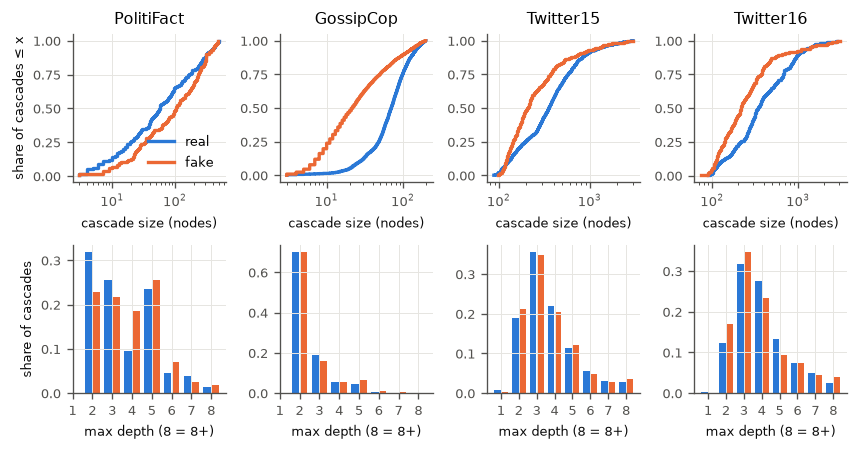

In [7]:
data = {}
for n in DATASETS:
    g = graphs_all[n]
    g = g[g.label_binary.notna()].astype({"label_binary": int}).set_index("graph_id")
    v = nodes_all[n]
    data[n] = (g, v[v.graph_id.isin(g.index) & (v.node_idx > 0)])  # v = engagements only (root excluded)

fig, ax = panels(2)
for j, (n, (g, v)) in enumerate(data.items()):
    for y in (0, 1):
        ecdf(ax[0, j], g.n_nodes[g.label_binary == y], COLOR[y], NAME[y])
    ax[0, j].set(xscale="log", title=TITLE[n], xlabel="cascade size (nodes)")
    d = pd.crosstab(g.max_depth.clip(upper=8), g.label_binary, normalize="columns")
    for k, y in enumerate((0, 1)):
        ax[1, j].bar(d.index + (k - 0.5) * 0.4, d[y], width=0.38, color=COLOR[y])
    ax[1, j].set(xlabel="max depth (8 = 8+)", xticks=range(1, 9))
ax[0, 0].set_ylabel("share of cascades ≤ x")
ax[1, 0].set_ylabel("share of cascades")
ax[0, 0].legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "fig1_size_depth.png")

In [8]:
rows = []
for n, (g, v) in data.items():
    rc = v.assign(rc=v.parent_idx == 0).groupby("graph_id").rc.mean()
    for y in (0, 1):
        s = g[g.label_binary == y]
        rows.append({"dataset": TITLE[n], "class": NAME[y], "cascades": len(s), "median nodes": s.n_nodes.median(),
                     "median depth": s.max_depth.median(), "median span (h)": round(s.t_span_min.median() / 60, 1),
                     "median share of root children": round(rc[s.index].median(), 2)})
pd.DataFrame(rows).set_index(["dataset", "class"])

cascades  median nodes  median depth  median span (h)  \
dataset    class                                                          
PolitiFact real        157          58.0           3.0          23524.8   
           fake        157         104.0           4.0           2810.6   
GossipCop  real       2732          70.0           2.0            130.9   
           fake       2732          22.0           2.0            486.2   
Twitter15  real        746         355.0           3.0            267.9   
           fake        370         208.5           3.0            171.0   
Twitter16  real        412         341.5           4.0            162.5   
           fake        205         215.0           3.0            242.0   

                  median share of root children  
dataset    class                                 
PolitiFact real                            0.64  
           fake                            0.61  
GossipCop  real                            0.93  
           fake                            0.79  
Twitter15  real                            0.87  
           fake                            0.84  
Twitter16  real                            0.83  
           fake                            0.81

* **Size depends on the class, but not consistently:** fake cascades are smaller in GossipCop (median 22 vs 70
  nodes) and Twitter (~210 vs ~350), larger in PolitiFact (104 vs 58). Size alone is therefore a strong but
  dataset-specific cue, and a size-only baseline is mandatory.
* **Trees are shallow and star-like:** most nodes hang directly under the root (median share of root children
  0.6-0.9; 70 % of GossipCop cascades have depth 2). Depth distributions of fake and real overlap heavily.

## 3. How fast do cascades grow?
For each cascade: share of its final size already observed *t* hours after the first post
(median and interquartile range per class; dotted lines at 1 h and 24 h).

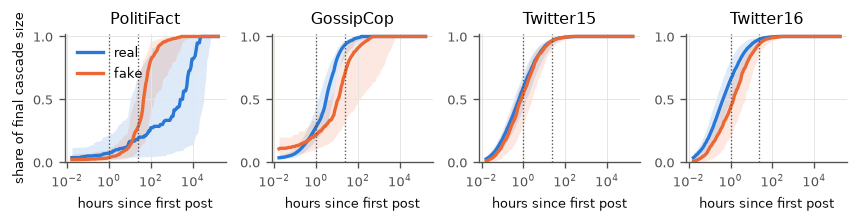

In [9]:
fig, ax = panels()
grid = np.logspace(0, 7, 140)  # minutes: 1 min .. ~19 years
for j, (n, (g, v)) in enumerate(data.items()):
    t = v.sort_values("t_min").groupby("graph_id").t_min.apply(np.asarray)
    for y in (0, 1):
        ids = g.index[g.label_binary == y]
        frac = np.array([(np.searchsorted(t[i], grid, side="right") + 1) / g.n_nodes[i] for i in ids])
        q25, q50, q75 = np.percentile(frac, [25, 50, 75], axis=0)
        ax[0, j].fill_between(grid / 60, q25, q75, color=COLOR[y], alpha=0.15, lw=0)
        ax[0, j].plot(grid / 60, q50, color=COLOR[y], label=NAME[y])
    for hh in (1, 24):
        ax[0, j].axvline(hh, color=INK2, lw=0.8, ls=":")
    ax[0, j].set(xscale="log", title=TITLE[n], xlabel="hours since first post", ylim=(0, 1.02))
ax[0, 0].set_ylabel("share of final cascade size")
ax[0, 0].legend(loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "fig2_growth.png")

In [10]:
H = [1 / 6, 1, 6, 24, 168]
avail = {}
for n, (g, v) in data.items():
    for h in H:
        c = v[v.t_min <= h * 60].groupby("graph_id").size().reindex(g.index, fill_value=0)
        avail[(TITLE[n], wlabel(h))] = {"median engagements": np.median(c),
                                        "median share of final size": np.median((c + 1) / g.n_nodes),
                                        "cascades with >= 10 engagements": (c >= 10).mean()}
pd.DataFrame(avail).T

median engagements  median share of final size  \
PolitiFact 10 min                 1.0                       0.038   
           1 h                    2.0                       0.054   
           6 h                    3.5                       0.104   
           24 h                  10.0                       0.250   
           168 h                 21.0                       0.750   
GossipCop  10 min                 3.0                       0.116   
           1 h                    8.0                       0.251   
           6 h                   17.0                       0.520   
           24 h                  29.0                       0.875   
           168 h                 35.0                       0.990   
Twitter15  10 min                69.0                       0.251   
           1 h                  154.0                       0.581   
           6 h                  241.0                       0.866   
           24 h                 280.0                       0.967   
           168 h                299.5                       0.998   
Twitter16  10 min                77.0                       0.266   
           1 h                  164.0                       0.595   
           6 h                  237.0                       0.866   
           24 h                 279.0                       0.967   
           168 h                296.0                       0.999   

                   cascades with >= 10 engagements  
PolitiFact 10 min                            0.029  
           1 h                               0.134  
           6 h                               0.299  
           24 h                              0.513  
           168 h                             0.611  
GossipCop  10 min                            0.117  
           1 h                               0.465  
           6 h                               0.603  
           24 h                              0.711  
           168 h                             0.764  
Twitter15  10 min                            0.903  
           1 h                               0.975  
           6 h                               0.988  
           24 h                              0.991  
           168 h                             0.995  
Twitter16  10 min                            0.906  
           1 h                               0.971  
           6 h                               0.997  
           24 h                              1.000  
           168 h                             1.000

* **The time scale differs by orders of magnitude.** After 1 h a Twitter cascade has ~60 % of its final size
  (median ~160 engagements), GossipCop ~25 %, PolitiFact only ~5 % (median 2 engagements); PolitiFact real
  cascades keep growing for years.
* Consequence for the project: a fixed "first *h* hours" window is not comparable across datasets. We will
  evaluate both **time windows with a per-dataset grid** and **count windows (first *k* engagements)**.
* The shapes differ by class: in GossipCop and Twitter16 real cascades saturate earlier than fake ones;
  in PolitiFact it is the other way round.

## 4. Which early signals separate fake from real?
For a window of *h* hours we compute three simple cascade features and measure how well each one alone
separates the classes (ROC AUC, direction-free; 0.5 = no signal). "full" = whole cascade.

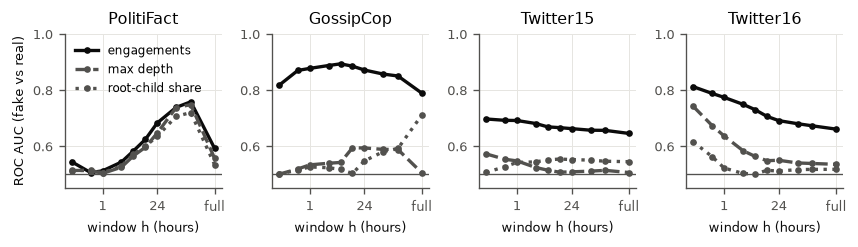

In [11]:
WINDOWS_H = [1 / 6, 0.5, 1, 3, 6, 12, 24, 72, 168]
STYLES = {"engagements": dict(color=INK, ls="-"), "max depth": dict(color=INK2, ls="--"),
          "root-child share": dict(color=INK2, ls=":")}


def window_features(g, v, h):
    w = v if h is None else v[v.t_min <= h * 60]
    grp = w.assign(root_child=w.parent_idx == 0).groupby("graph_id")
    f = pd.DataFrame({"engagements": grp.size(), "max depth": grp.depth.max(),
                      "root-child share": grp.root_child.mean()})
    return f.reindex(g.index).fillna(0)


fig, ax = panels(h=2.1)
auc_rows = []
for j, (n, (g, v)) in enumerate(data.items()):
    xs = WINDOWS_H + [WINDOWS_H[-1] * 4]  # plot position of "full"
    res = {c: [] for c in STYLES}
    for h in WINDOWS_H + [None]:
        f = window_features(g, v, h)
        for c in STYLES:
            res[c].append(auc(g.label_binary, f[c]))
            auc_rows.append({"dataset": TITLE[n], "feature": c, "window": wlabel(h),
                             "AUC": res[c][-1]})
    for c, s in STYLES.items():
        ax[0, j].plot(xs, res[c], marker="o", ms=3, label=c, **s)
    ax[0, j].axhline(0.5, color=INK2, lw=0.8)
    ax[0, j].set(xscale="log", title=TITLE[n], ylim=(0.45, 1), xlabel="window h (hours)",
                 xticks=[1, 24, xs[-1]], xticklabels=["1", "24", "full"])
ax[0, 0].set_ylabel("ROC AUC (fake vs real)")
ax[0, 0].legend(loc="upper left", fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "fig3_auc_by_window.png")

In [12]:
pd.DataFrame(auc_rows).pivot_table(index=["dataset", "feature"], columns="window", values="AUC", sort=False)

window                       10 min  30 min    1 h    3 h    6 h   12 h  \
dataset    feature                                                        
PolitiFact engagements        0.544   0.506  0.512  0.543  0.583  0.624   
           max depth          0.513   0.514  0.503  0.525  0.565  0.596   
           root-child share   0.514   0.513  0.506  0.529  0.571  0.600   
GossipCop  engagements        0.816   0.870  0.877  0.888  0.893  0.885   
           max depth          0.500   0.519  0.533  0.539  0.542  0.594   
           root-child share   0.501   0.515  0.526  0.523  0.517  0.503   
Twitter15  engagements        0.697   0.692  0.692  0.681  0.669  0.666   
           max depth          0.573   0.553  0.548  0.524  0.514  0.507   
           root-child share   0.506   0.527  0.542  0.544  0.551  0.554   
Twitter16  engagements        0.812   0.788  0.774  0.749  0.730  0.706   
           max depth          0.742   0.673  0.636  0.584  0.564  0.548   
           root-child share   0.615   0.563  0.522  0.503  0.500  0.514   

window                        24 h   72 h  168 h   full  
dataset    feature                                       
PolitiFact engagements       0.683  0.738  0.758  0.592  
           max depth         0.647  0.738  0.748  0.557  
           root-child share  0.635  0.706  0.720  0.534  
GossipCop  engagements       0.871  0.857  0.850  0.789  
           max depth         0.594  0.589  0.588  0.505  
           root-child share  0.547  0.581  0.592  0.711  
Twitter15  engagements       0.663  0.657  0.656  0.645  
           max depth         0.509  0.511  0.514  0.506  
           root-child share  0.552  0.550  0.546  0.545  
Twitter16  engagements       0.691  0.680  0.673  0.661  
           max depth         0.550  0.540  0.538  0.535  
           root-child share  0.511  0.517  0.517  0.518

* **The number of engagements is a strong baseline and often stronger early than on the full cascade:**
  GossipCop AUC 0.89 at 6 h vs 0.79 on the full cascade, Twitter16 0.81 after 10 minutes vs 0.66.
  Early activity carries information that is diluted later. The "number of shares" baseline from our proposal
  must therefore be computed per window; graph and sequence models have to beat it at the same window.
* **Tree shape carries little signal early:** max depth and the share of root children stay at AUC 0.5-0.6
  in most windows (exceptions: Twitter16 in the first minutes, PolitiFact after ~1 week).
  Early trees are mostly stars, so any advantage of a GNN over a sequence model is more likely to come from
  node features and timing than from topology. This is a hypothesis we will test, not a result.
* PolitiFact needs days: no feature separates the classes in the first hours (few engagements, section 3).

## 5. Speed of the first engagements
Time until the 5th engagement (cascades with fewer engagements are left out).

,"median minutes, real","median minutes, fake",AUC,cascades used
PolitiFact,1858.083,358.542,0.620,302
GossipCop,7.925,298.683,0.850,5318
Twitter15,0.730,1.500,0.702,1116
Twitter16,0.560,1.720,0.815,617


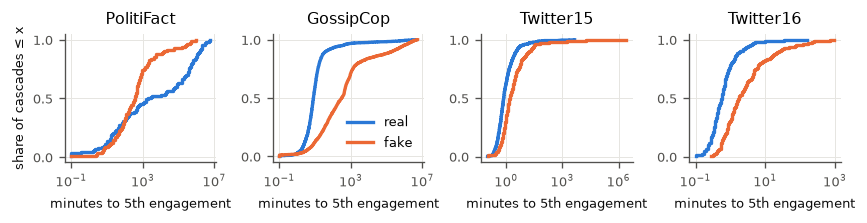

In [13]:
K = 5
fig, ax = panels()
rows = {}
for j, (n, (g, v)) in enumerate(data.items()):
    tk = v[v.node_idx == K].set_index("graph_id").t_min.reindex(g.index)
    m = tk.notna()
    for y in (0, 1):
        ecdf(ax[0, j], tk[m & (g.label_binary == y)].clip(lower=0.1), COLOR[y], NAME[y])
    rows[TITLE[n]] = {"median minutes, real": tk[g.label_binary == 0].median(),
                      "median minutes, fake": tk[g.label_binary == 1].median(),
                      "AUC": auc(g.label_binary[m], tk[m]), "cascades used": int(m.sum())}
    ax[0, j].set(xscale="log", title=TITLE[n], xlabel=f"minutes to {K}th engagement")
ax[0, 0].set_ylabel("share of cascades ≤ x")
ax[0, 1].legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "fig4_time_to_k.png")
pd.DataFrame.from_dict(rows, orient="index").astype({"cascades used": int})

* **In these datasets fake content starts *slower*, not faster.** The 5th engagement arrives after a median
  8 min for real vs ~5 h for fake news in GossipCop (AUC 0.85 from this single number), and after ~0.7 vs
  ~1.6 min in Twitter. This runs against the common "fake news spreads faster" narrative; a plausible reason is
  that real stories come from large mainstream accounts with immediate reach. PolitiFact differs again
  (fake faster after the first hours).
* Timing is therefore a first-class signal; it supports encoding retweet timestamps in both of our
  representations (time features on nodes for the GNN, inter-arrival times for the GRU).

## 6. Users shared between cascades
Do the same users take part in several cascades, and are they class-consistent? For users present in more than
one cascade we compute the share that appear only in fake or only in real cascades, and compare it with the same
statistic after randomly shuffling the cascade labels (20 permutations).

In [14]:
def purity(ul, lab):
    d = ul.assign(y=ul.graph_id.map(lab).values).groupby("user_id").y.agg(["size", "mean"])
    d = d[d["size"] > 1]
    return ((d["mean"] == 0) | (d["mean"] == 1)).mean(), len(d)


rng = np.random.default_rng(0)
rows = {}
for n, (g, v) in data.items():
    ul = v[["graph_id", "user_id"]].drop_duplicates()
    obs, n_multi = purity(ul, g.label_binary)
    null = [purity(ul, pd.Series(rng.permutation(g.label_binary.values), index=g.index))[0] for _ in range(20)]
    rows[TITLE[n]] = {"users": ul.user_id.nunique(), "users in > 1 cascade": n_multi,
                      "single-class share": obs, "single-class share, shuffled labels": np.mean(null)}
pd.DataFrame(rows).T.astype({"users": int, "users in > 1 cascade": int})

,users,users in > 1 cascade,single-class share,"single-class share, shuffled labels"
PolitiFact,30812,2953,0.815,0.413
GossipCop,75914,15646,0.604,0.298
Twitter15,407380,46950,0.718,0.459
Twitter16,242129,24300,0.706,0.470


* 10-20 % of users take part in more than one cascade, and they are strongly class-consistent: 60-82 % of them
  appear in only one class versus 30-47 % expected by chance. Users who spread fake news keep spreading it.
* This is a useful signal (it explains why UPFD's user-history features work well) and also a **leakage
  channel**: if the same users appear in training and test cascades, a model can memorise users instead of
  learning propagation patterns. We will report results with this in mind (e.g. a user-disjoint check).

## 7. Summary and implications for the project
1. Four datasets, two domains (news articles, Twitter rumours), two label schemes; aligned to one tree format.
2. Growth speed differs by orders of magnitude across datasets → evaluate **per-dataset time grids and
   first-*k* windows**.
3. Early engagement counts and arrival times are strong single features; the **count baseline must be
   computed per window** and beaten at the same window.
4. Early trees are star-like and their shape alone separates the classes poorly → the graph vs. sequence
   comparison should isolate the contribution of topology (same node features in both).
5. Leakage sources (Twitter15/16 overlap, duplicate texts/cascades, shared users) must be controlled by grouped
   splits.